In [1]:
from article_utils.util import read_jsonl


# df = read_jsonl(f'../builds/civicfact-{build_version}/data.jsonl.gz')
df = read_jsonl('../builds/civicfact-2026.03.03/data.jsonl.gz')
# df = df[df.partition != 'unassigned']
print(df.columns.tolist())
df.head()


['balance_args.maximization_factor', 'balance_args.ngram', 'civic.claim', 'civic.claim.flat', 'civic.corrections', 'civic.description', 'civic.events', 'civic.evidenceDirection', 'civic.evidenceLevel', 'civic.evidenceRating', 'civic.evidenceType', 'civic.flagged', 'civic.ground_truth', 'civic.id', 'civic.lastUpdatedAt', 'civic.revision_note', 'civic.revision_state', 'civic.status', 'claim', 'claim.flat', 'claim.generated', 'claim.id', 'claim.source', 'conversation', 'description.scores', 'description.status', 'display_id', 'document.doi', 'document.license', 'document.pmcid', 'document.pmid', 'document.title', 'evidence', 'evidence.flat', 'evidence.generated', 'evidence.id', 'evidence.selection_method', 'evidence.source', 'example', 'flagged', 'generated', 'gold_label_name', 'hypothesis.label', 'hypothesis.tag', 'hypothesis.tag_id', 'hypothesis.username', 'id', 'in_table', 'partition', 'pmid.partition', 'prebalancing_set', 'reviews', 'revised_claim.flat', 'row_index']


,balance_args.maximization_factor,balance_args.ngram,civic.claim,civic.claim.flat,civic.corrections,civic.description,civic.events,civic.evidenceDirection,civic.evidenceLevel,civic.evidenceRating,...,hypothesis.tag_id,hypothesis.username,id,in_table,partition,pmid.partition,prebalancing_set,reviews,revised_claim.flat,row_index
0,3.0,2,{'content': {'disease': 'Juvenile Polyposis Sy...,"{\n ""disease"": ""Juvenile Polyposis Syndrome"",...",NaN,The goal of this study was to find out if ther...,"[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,C,1.0,...,"[creisle, 6446, 1, default]",creisle,da496867-446e-42eb-9de8-2fb6c319cc93,True,unassigned,train,True,[],NaN,1337
1,3.0,2,{'content': {'disease': 'Renal Cell Carcinoma'...,"{\n ""disease"": ""Renal Cell Carcinoma"",\n ""ev...",NaN,A case study showed that the mTOR inhibitor ev...,"[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,C,1.0,...,"[creisle, 10137, 1, default]",creisle,089fd656-e703-4b4a-a075-9f3782df628f,True,unassigned,dev,True,[],NaN,1812
2,3.0,2,"{'content': {'disease': 'Ovarian Cancer', 'evi...","{\n ""disease"": ""Ovarian Cancer"",\n ""evidence...",NaN,"The ABCB1 G2677T/A (S893T, rs2032582) homozygo...","[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,B,3.0,...,"[creisle, 674, 1, default]",creisle,5c46a3d5-d79e-4ec6-b01d-45043c811b95,True,unassigned,train,True,[],NaN,1494
3,3.0,2,{'content': {'disease': 'Lung Non-small Cell C...,"{\n ""disease"": ""Lung Non-small Cell Carcinoma...",NaN,Samples from 393 patients with NSCLC were eval...,"[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,B,2.0,...,"[creisle, 1637, 1, default]",creisle,dab3f82c-86cf-480d-ab6e-d178c93738bc,True,unassigned,train,True,[],NaN,1321
4,3.0,2,{'content': {'disease': 'Lung Non-small Cell C...,"{\n ""disease"": ""Lung Non-small Cell Carcinoma...",NaN,The XRCC1 R194W variant was shown to be correl...,"[{'action': 'REVISION_ACCEPTED', 'createdAt': ...",SUPPORTS,B,4.0,...,"[creisle, 659, 1, NEI]",creisle,6b912510-d8d0-4d09-aaa1-e0c17e5f4932,True,unassigned,dev,True,[],NaN,648


## What do we have for retrieval data manually annotated by hypothesis?

In [2]:
## retrieval data
import pandas as pd

ret_df = df[(df['evidence.selection_method'] == 'hypothesis') & (df['evidence.source'] != 'civic') & (df['generated'] == False) & (df['gold_label_name'] != 'REVISIONS')].copy()

ev_df = ret_df.explode('evidence')
ev_df['passage_id'] = ev_df['document.pmid'] + ':' + ev_df.evidence.str['meta'].str['start'].astype(str) + '-' + ev_df.evidence.str['meta'].str['end'].astype(str)

ev_df['non_abstract_id'] = ev_df['document.pmid']
ev_df.loc[ev_df['evidence.source'] == 'pubmed', 'non_abstract_id'] = None

hard_df = read_jsonl('../../experiments/data/civicfact-2026.03.03/filters.hard.jsonl.gz').merge(ev_df)
hard_df['subset'] = ' [hard]'

ev_df = pd.concat([ev_df, hard_df])
ev_df['subset'] = ev_df['subset'].fillna('')
ev_df['label'] = ev_df['partition'] + ev_df['subset']
ev_df = ev_df.rename(columns={'claim.flat': 'claims', 'document.pmid': 'documents', 'non_abstract_id': 'documents (full-text only)', 'passage_id': 'passages', 'civic.id': "CIViC entries"})

ev_df = ev_df.groupby('label').agg({'CIViC entries': 'nunique',  'passages': 'nunique',  'documents': 'nunique','documents (full-text only)': 'nunique'}).T
ev_df[['train', 'train [hard]', 'dev', 'dev [hard]', 'test', 'test [hard]', 'unassigned']]

label,train,train [hard],dev,dev [hard],test,test [hard],unassigned
CIViC entries,907,490,99,34,88,35,255
passages,1645,800,188,53,172,69,549
documents,429,164,65,19,42,15,186
documents (full-text only),366,164,57,19,34,15,156


In [3]:
ver_df= df.copy()
ver_df['pairs'] = ver_df['claim.flat'] + ver_df['evidence.flat'] + ver_df['document.pmid']
print(ver_df.groupby('partition').agg({'claim.flat': 'nunique', 'document.pmid': 'nunique', 'pairs': 'nunique'}))
print(ver_df.groupby(['partition', 'gold_label_name']).agg({'pairs': 'nunique'}))

            claim.flat  document.pmid  pairs
partition                                   
dev                845            183   1006
test               779            138   1001
train             7418           1068   9271
unassigned         531            325    720
                            pairs
partition  gold_label_name       
dev        NEI                345
           REVISIONS          343
           SUPPORTS           318
test       NEI                342
           REVISIONS          339
           SUPPORTS           320
train      NEI               3222
           REVISIONS         3182
           SUPPORTS          2867
unassigned NEI                 50
           REVISIONS          381
           SUPPORTS           289


In [4]:
# table 1




hard_df = read_jsonl('../../experiments/data/civicfact-2026.03.03/filters.hard.jsonl.gz').merge(df)
hard_df['subset'] = ' [hard]'
ver_df= df.copy()
ver_df['subset'] = ''

stats_df = pd.concat([ver_df, hard_df])
stats_df['label'] = stats_df['partition'].fillna('') + stats_df['subset'].fillna('')
stats_df['claim/evidence pairs'] = stats_df['claim.flat'] + stats_df['evidence.flat'] + stats_df['document.pmid']

for label in ['NEI', 'SUPPORTS', 'REVISIONS']:
    stats_df[label] = stats_df['claim/evidence pairs']
    stats_df.loc[stats_df.gold_label_name != label, label] = None
stats_df = stats_df.rename(columns={'claim.flat': 'claims', 'document.pmid': 'documents'})
stats_df = stats_df.groupby(['label'], dropna=False).agg({'claims': 'nunique',  'documents': 'nunique', 'claim/evidence pairs': 'nunique','NEI': 'nunique', 'REVISIONS': 'nunique', 'SUPPORTS': 'nunique' }).T
stats_df = stats_df[['train', 'train [hard]', 'dev', 'dev [hard]', 'test', 'test [hard]', 'unassigned']]
stats_df


label,train,train [hard],dev,dev [hard],test,test [hard],unassigned
claims,7418,2109,845,162,779,199,531
documents,1068,214,183,26,138,19,325
claim/evidence pairs,9271,2432,1006,182,1001,231,720
NEI,3222,68,345,1,342,3,50
REVISIONS,3182,1496,343,114,339,159,381
SUPPORTS,2867,868,318,67,320,69,289


In [5]:
# license distributition
df[['document.license', 'evidence.source']].value_counts()

document.license  evidence.source    
CC BY             pmc                    2648
                  pmc_author_fulltext    2477
none              pmc                     688
                  pubmed                  565
CC BY-NC-ND       pmc                     511
CC BY-NC          pmc                     500
CC BY-NC-SA       pmc                     148
CC0               pmc                      12
Name: count, dtype: int64

How many entries are manually curated vs auto-generated? 

In [ ]:
from article_utils.util import normalize_and_expand_column
import itertools

df = df[df.partition != 'unassigned']
assert df['id'].nunique() == df.shape[0]
manual_df = df[(df['evidence.selection_method'] == 'hypothesis') & (df['evidence.source'] != 'civic') & (df['generated'] == False) & (df['gold_label_name'] != 'REVISIONS')].copy()
print(manual_df.columns.tolist())
# manual_df = df[(df.generated != True) & (df['evidence.source'] != 'civic') & (df['evidence.selection_method'] == 'hypothesis')]
print(f'there are {df.shape[0]} total examples')
print(f'there are {manual_df.shape[0]} manually curated examples from hypothesis')
print(f'these cover {manual_df["civic.id"].nunique()} civic entries')
print(f'these cover {manual_df["document.pmid"].nunique()} pubmed IDs')

dev_df = manual_df[manual_df.partition =='dev'].copy()
dev_df['conversation_tags'] = dev_df.conversation.apply(lambda conv: set(itertools.chain.from_iterable(c['tags'] for c in conv)))
dev_df['conversation_tags'] = dev_df['conversation_tags'].apply(lambda ct: {t for t in ct if 'eid' not in t.lower()})
dev_df['not_in_main_text'] = dev_df.conversation_tags.apply(lambda ct: bool({'requires-supplement', 'requires-image'} & ct))
print('entries in the dev partition', dev_df['civic.id'].nunique())
print(dev_df['evidence.source'].value_counts())
dev_df = dev_df[dev_df['evidence.source'] != 'pubmed']
print('entries in the dev partition with insufficient evidence', dev_df[dev_df.not_in_main_text == True]['civic.id'].nunique())

dev_df.groupby(['partition', 'gold_label_name']).agg({'civic.id': 'nunique'})


['balance_args.maximization_factor', 'balance_args.ngram', 'civic.claim', 'civic.claim.flat', 'civic.corrections', 'civic.description', 'civic.events', 'civic.evidenceDirection', 'civic.evidenceLevel', 'civic.evidenceRating', 'civic.evidenceType', 'civic.flagged', 'civic.ground_truth', 'civic.id', 'civic.lastUpdatedAt', 'civic.revision_note', 'civic.revision_state', 'civic.status', 'claim', 'claim.flat', 'claim.generated', 'claim.id', 'claim.source', 'conversation', 'description.scores', 'description.status', 'display_id', 'document.doi', 'document.license', 'document.pmcid', 'document.pmid', 'document.title', 'evidence', 'evidence.flat', 'evidence.generated', 'evidence.id', 'evidence.selection_method', 'evidence.source', 'example', 'flagged', 'generated', 'gold_label_name', 'hypothesis.label', 'hypothesis.tag', 'hypothesis.tag_id', 'hypothesis.username', 'id', 'in_table', 'partition', 'pmid.partition', 'prebalancing_set', 'reviews', 'revised_claim.flat', 'row_index', 'evidence_type', 

civic.id
partition gold_label_name          
dev       NEI                     6
          SUPPORTS               83

In [7]:
# make a preview of a row in the dataset
import json


df['valid_reviews'] = df.reviews.apply(lambda revs: [r for r in revs if r['reason'] and r['username'] not in {'bot', 'creisle'} and len(r['reason']) > 100])
for _, row in df[(df.generated == False) & (df.valid_reviews.str.len() > 1)].iterrows():
    for review in row.reviews:
        if review['reason'] and review['username'] not in {'bot', 'creisle'}:
            print(row['id'])
            print(review['reason'])

df = df.drop(columns=['valid_reviews'])

for _, row in df[df['id'] == '15af113a-59b6-4fdf-a1d5-bbd0b7248d92'].iterrows():
    print(json.dumps(dict(row)))

What is the curation distribution per user?

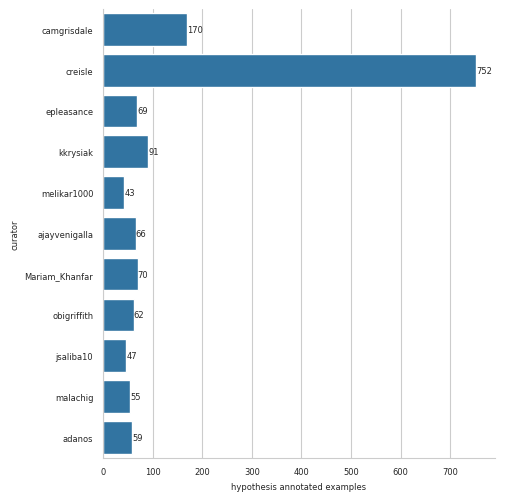

In [8]:
import seaborn as sns
from figutils import add_bar_labels

sns.set_style('whitegrid')
fig = sns.catplot(manual_df, y='hypothesis.username', kind='count')
fig.set(xlabel='hypothesis annotated examples', ylabel='curator')
add_bar_labels(fig)

How about the annotations themselves? What parts of the paper do users generally select?

Empty DataFrame
Columns: [document.pmcid, evidence.flat, evidence.source, section]
Index: []


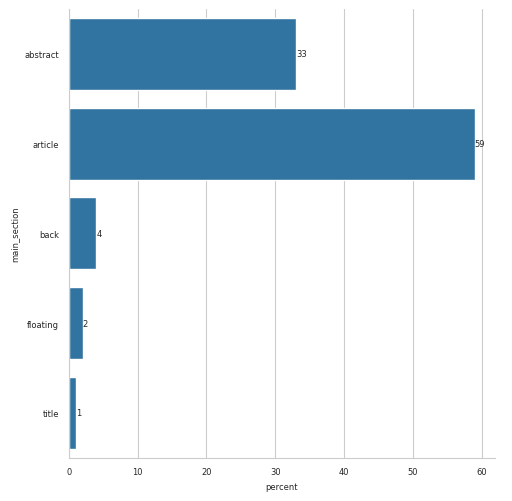

In [9]:
fig_df = manual_df.copy()
fig_df = fig_df.explode(['evidence'])
fig_df['section'] = fig_df.evidence.str['meta'].str['section'].str.split(';')
fig_df = fig_df.explode(['section'])
fig_df['section'] = fig_df.section.fillna('')
fig_df['section'] = fig_df['section'].str.split('.').str[0]
fig_df['freq'] = 1
totals = (
    fig_df.groupby(['id'])
    .agg({'freq': 'sum'})
    .reset_index()
    .rename(columns={'freq': 'total'})
)
fig_df = fig_df.merge(totals)
fig_df['examples'] = 1 / fig_df['total']


fig_df['main_section'] = fig_df.section.str.split('//').str[0]
print(fig_df[fig_df['main_section'] == ''][['document.pmcid', 'evidence.flat', 'evidence.source', 'section']])
fig_df = fig_df.groupby(['main_section']).agg({'examples': 'sum'}).reset_index()
fig_df['examples'] = fig_df.examples.round()
fig_df['percent'] = (100 * fig_df.examples / manual_df.shape[0]).round()

fig_df = fig_df[fig_df.examples > 0]

fig = sns.catplot(fig_df, x='percent', y='main_section', kind='bar')
add_bar_labels(fig)


abstract_only
False    0.729459
True     0.270541
Name: proportion, dtype: float64


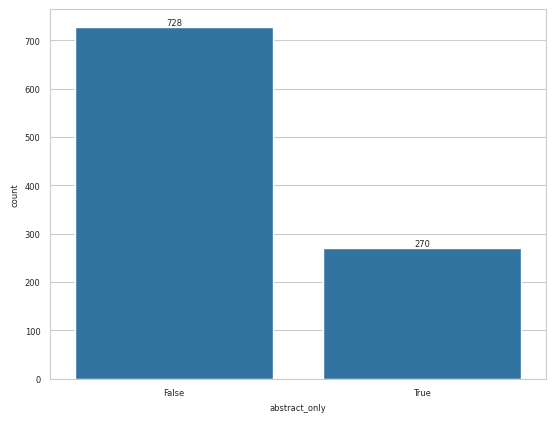

In [10]:
# how many claims in CIViC require text  from outside the abstract or title

fig_df = manual_df.drop_duplicates(['civic.id'])
fig_df = fig_df.explode(['evidence'])
fig_df['section'] = fig_df.evidence.str['meta'].str['section'].str.split(';')
fig_df = fig_df.explode(['section'])
fig_df['section'] = fig_df.section.fillna('')
fig_df['section'] = fig_df['section'].str.split('.').str[0]
fig_df['main_section'] = fig_df.section.str.split('//').str[0]
fig_df.loc[fig_df['evidence.source'] =='pubmed', 'main_section'] = 'abstract'
fig_df.loc[fig_df.main_section == 'title', 'main_section'] = 'abstract'
fig_df = fig_df[fig_df.gold_label_name != 'NEI']

fig_df = fig_df.groupby(['civic.id', 'document.pmid', 'id']).agg({'main_section': 'unique'}).reset_index()
fig_df['abstract_only'] = (fig_df.main_section.str.len() == 1) & (fig_df.main_section.str[0] == 'abstract')
fig_df = fig_df.groupby(['civic.id', 'document.pmid']).agg({'abstract_only': 'any'}).reset_index()

print(fig_df['abstract_only'].value_counts(normalize=True))


fig = sns.countplot(fig_df, x='abstract_only')
add_bar_labels(fig)

how does the split look across partitions? across labels?

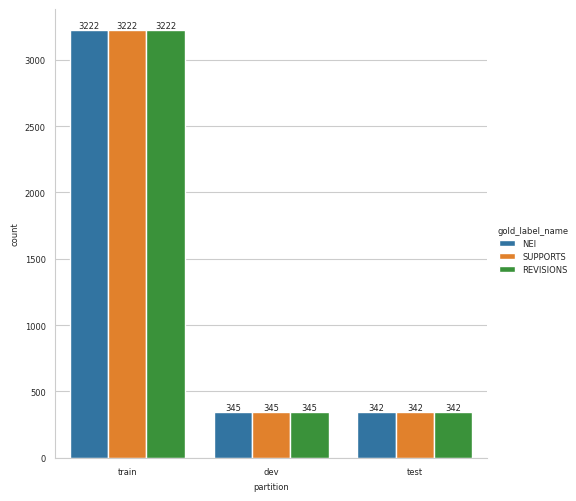

In [11]:
fig = sns.catplot(df, x='partition', hue='gold_label_name', kind='count')
add_bar_labels(fig)

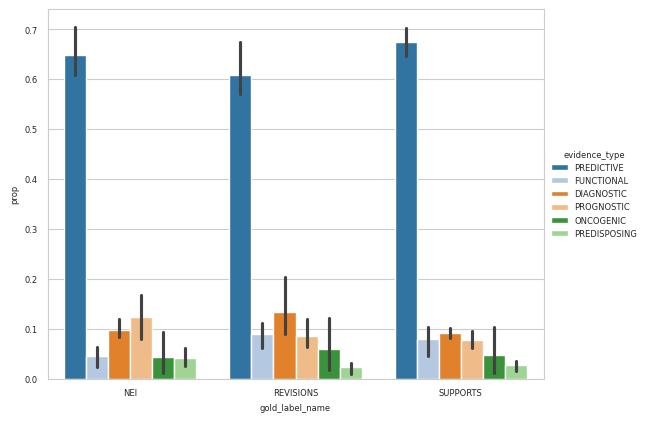

In [12]:
def get_claim_col(claim, target_col, strict=True):
    header, row = claim.split('\n')
    for col, val in zip(header.split('\t'), row.split('\t')):
        if col == target_col:
            return val
    if strict:
        raise KeyError(f'target column does not exist in claim: {target_col}')
    return None

df['evidence_type'] = df['claim'].str['content'].str['evidenceType']
df['significance'] = df['claim'].str['content'].str['significance']
df['freq'] = 1

fig_df = df[['evidence_type', 'partition', 'gold_label_name']].value_counts().reset_index(name='freq').merge(df[['partition', 'gold_label_name']].value_counts().reset_index(name='label_freq'))
fig_df['prop'] = fig_df.freq / fig_df.label_freq

ax = sns.barplot(fig_df, x='gold_label_name', y='prop', hue='evidence_type', palette='tab20')
sns.move_legend(ax, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
